In [1]:
dataset_path = r'C:\Users\Asus\Desktop\progetto_caravaggio\dataset\originali\caravaggio'
#dataset_path = '/content/drive/MyDrive/Aridataset/caravaggio_2/caravaggio_bw/caravaggio_cropped/FemaleCaravaggio'

In [2]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.5.1+cu121
True
NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
import os
os.environ["PYTHONNOUSERSITE"] = "1"

import torch
import cv2
import onnxruntime as ort
from deepface import DeepFace

print("PyTorch CUDA:", torch.cuda.is_available(), f"({torch.cuda.get_device_name(0)})")
print("OpenCV Version:", cv2.__version__)
print("ONNX Providers:", ort.get_available_providers())
print("DeepFace caricato con successo!")


PyTorch CUDA: True (NVIDIA GeForce RTX 4060 Laptop GPU)
OpenCV Version: 4.10.0
ONNX Providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
DeepFace caricato con successo!


In [4]:
import os
import torch
import numpy as np
import torchvision.transforms as T
import hdbscan
import math
import umap
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.image as mpimg
from PIL import Image
from tqdm import tqdm
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity


In [5]:
model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

model.eval()

print("DINOv2 pronto all'uso senza aver clonato il repo!")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to C:\Users\Asus/.cache\torch\hub\main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to C:\Users\Asus/.cache\torch\hub\checkpoints\dinov2_vitb14_pretrain.pth
100%|██████████| 330M/330M [03:28<00:00, 1.66MB/s] 


DINOv2 pronto all'uso senza aver clonato il repo!


In [6]:
transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Estrazione di massa
all_embeddings = []
file_names = []

# Prendiamo solo i file che finiscono con estensioni immagine
valid_extensions = ('.jpg', '.jpeg', '.png', '.webp')
files = [f for f in os.listdir(dataset_path) if f.lower().endswith(valid_extensions)]

print(f"Inizio elaborazione di {len(files)} immagini...")

with torch.no_grad():
    for filename in tqdm(files):
        try:
            full_path = os.path.join(dataset_path, filename)

            # Caricamento e trasformazione
            img = Image.open(full_path).convert('RGB')
            img_t = transform(img).unsqueeze(0).to(device)

            # Estrazione embedding
            embedding = model(img_t)

            all_embeddings.append(embedding.cpu().numpy().flatten())
            file_names.append(filename)

        except Exception as e:
            print(f"Errore su {filename}: {e}")

# Conversione finale in Matrice
X = np.array(all_embeddings)

print(f"Matrice creata: {X.shape[0]} immagini x {X.shape[1]} caratteristiche.")

Inizio elaborazione di 24 immagini...


 17%|█▋        | 4/24 [00:01<00:04,  4.98it/s]

Errore su flagellazione_di_cristo.jpg: Image size (193600020 pixels) exceeds limit of 178956970 pixels, could be decompression bomb DOS attack.


100%|██████████| 24/24 [00:04<00:00,  5.48it/s]

Matrice creata: 23 immagini x 768 caratteristiche.


In [7]:
# Riduciamo i dati a 2 dimensioni per poterli visualizzare e clusterizzare meglio
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
X_embedded = reducer.fit_transform(X)

print("Riduzione completata. Ora ogni quadro è un punto in un grafico 2D.")

Riduzione completata. Ora ogni quadro è un punto in un grafico 2D.


In [8]:
# min_cluster_size: il numero minimo di quadri per formare un gruppo (es. 2 o 3)
clusterer = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=1, gen_min_span_tree=True)
labels = clusterer.fit_predict(X_embedded)

# Creiamo un DataFrame per vedere meglio i risultati
results = pd.DataFrame({
    'file': file_names,
    'cluster': labels
})

print(results.sort_values(by='cluster'))

                                                 file  cluster
1                    Davide_con_la_testa_di_golia.jpg       -1
5                          incoronazione_di_spine.jpg       -1
18                          riposo-fuga-in-egitto.jpg       -1
10                 Le_sette_opere_di_misericordia.jpg       -1
21                            san_matteo_e_angelo.jpg       -1
0                                  Cena_in_Emmaus.jpg        0
2                           Deposizione_di_cristo.jpg        0
4                             Giuditta_e_Olomerfe.png        0
8                          la_morte_della_vergine.JPG        0
9                      La_negazione_di_San_Pietro.jpg        0
13                            Madonna_del_rosario.jpg        0
14                              Madonna_di_Loreto.jpg        0
16                                       nativita.jpg        0
20                   Santa_caterina_d_alessandria.jpg        1
19  Salome_con_la_cabeza_del_Bautista_(Caravaggio)...  

ValueError: 'Unknown.tif' is not in list

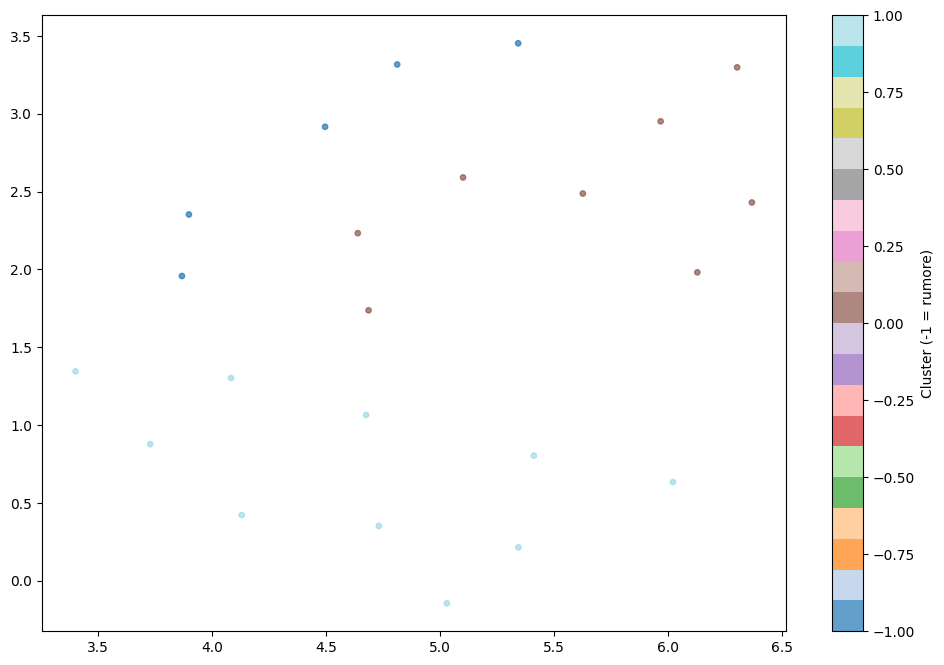

In [10]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1],
                      c=labels, cmap='tab20', s=15, alpha=0.7)
plt.colorbar(scatter, label='Cluster (-1 = rumore)')

idx_test = file_names.index("Unknown.tif")
plt.scatter(X_embedded[idx_test, 0], X_embedded[idx_test, 1],
            c='red', s=200, marker='*', zorder=5, label='Unknown.jpg')
plt.legend()

n_clusters_hdb = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_hdb = (labels == -1).sum()
plt.title(f'UMAP — HDBSCAN  |  {n_clusters_hdb} cluster  |  {n_noise_hdb} punti rumore')
plt.show()

In [ ]:
nome_file_cercato = "Unknown.jpg" # Metti il nome esatto del file che ti interessa

cluster_id = results.loc[results['file'] == nome_file_cercato, 'cluster'].values[0]
print(f"L'immagine '{nome_file_cercato}' appartiene al Cluster: {cluster_id}")

In [ ]:
# 1. Recupera l'ID del cluster per il file di test
cluster_id = results.loc[results['file'] == "Unknown.jpg", 'cluster'].values[0]

if cluster_id == -1:
    print("⚠️ L'immagine è classificata come RUMORE (nessun cluster trovato).")
else:
    # 2. Filtra tutti i file dello stesso cluster
    immagini_cluster = results[results['cluster'] == cluster_id]['file'].tolist()
    n_immagini = len(immagini_cluster)

    print(f"Il Cluster {cluster_id} contiene {n_immagini} immagini.")

    # 3. Configura la griglia (es. 5 immagini per riga)
    cols = 5
    rows = math.ceil(n_immagini / cols)

    plt.figure(figsize=(20, 4 * rows))

    for i, file_name in enumerate(immagini_cluster):
        plt.subplot(rows, cols, i + 1)
        img_path = os.path.join(dataset_path, file_name)

        try:
            img_bgr = cv2.imread(img_path)
            img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            plt.imshow(img)
            # Evidenziamo il file "test" con un titolo rosso
            title_color = 'red' if "test" in file_name.lower() else 'black'
            plt.title(file_name, fontsize=9, color=title_color)
        except Exception as e:
            plt.title(f"Errore: {file_name}", fontsize=8)

        plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:

# 1. Recuperiamo l'indice del file di test nella lista globale file_names
nome_test = "Unknown.jpg"
try:
    idx_test = file_names.index(nome_test)
    vettore_test = X[idx_test].reshape(1, -1)
except ValueError:
    print(f"Errore: il file {nome_test} non è stato trovato nella lista globale.")
    idx_test = None

if idx_test is not None:
    similarita_risultati = []

    # 2. Cicliamo su ogni nome file presente nella lista immagini_cluster
    for nome_file_Hdbscan in immagini_cluster:
        if nome_file_Hdbscan == nome_test:
            continue # Saltiamo il confronto del test con se stesso

        # Recuperiamo l'indice globale per questo file del cluster
        idx_confronto = file_names.index(nome_file_Hdbscan)
        vettore_confronto = X[idx_confronto].reshape(1, -1)

        # Calcoliamo la similarità (restituisce un valore tra 0 e 1)
        sim = cosine_similarity(vettore_test, vettore_confronto)[0][0]

        similarita_risultati.append({
            'Immagine': nome_file_Hdbscan,
            'Similarità Coseno': round(sim, 4)
        })

    # 3. Creiamo una tabella ordinata per le immagini più simili
    df_sim = pd.DataFrame(similarita_risultati)
    df_sim = df_sim.sort_values(by='Similarità Coseno', ascending=False)

    print(f"\n--- Analisi di Similarità per il Cluster del Test ({nome_test}) ---")
    if df_sim.empty:
        print("Il cluster contiene solo l'immagine di test.")
    else:
        print(df_sim.to_string(index=False))

    # 4. Calcolo della media del cluster (escludendo il test)
    if not df_sim.empty:
        media_cluster = df_sim['Similarità Coseno'].mean()
        print(f"\nSimilarità media del test con i membri del cluster: {media_cluster:.4f}")

In [ ]:
# ── K-Distance Plot per scegliere eps ─────────────────────────
min_samples = 3
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_embedded)
distances, _ = neighbors.kneighbors(X_embedded)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel('Punti ordinati')
plt.ylabel(f'Distanza dal {min_samples}° vicino')
plt.title('K-Distance Plot — scegli eps nel gomito')
plt.grid(True)
plt.show()

# ── DBSCAN ────────────────────────────────────────────────────
# Modifica eps dopo aver osservato il gomito nel grafico sopra
eps = 0.50

clusterer_db = DBSCAN(eps=eps, min_samples=min_samples)
labels_db = clusterer_db.fit_predict(X_embedded)

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = (labels_db == -1).sum()
print(f"DBSCAN — Cluster trovati: {n_clusters_db}  |  Punti rumore: {n_noise_db}")
# ── Visualizzazione UMAP colorata ─────────────────────────────
plt.figure(figsize=(12, 8))
scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1],
                      c=labels_db, cmap='tab20', s=15, alpha=0.7)
plt.colorbar(scatter, label='Cluster (-1 = rumore)')

idx_test = file_names.index("Unknown.jpg")
plt.scatter(X_embedded[idx_test, 0], X_embedded[idx_test, 1],
            c='red', s=200, marker='*', zorder=5, label='Unknown.jpg')
plt.legend()

plt.title(f'UMAP — DBSCAN  |  eps={eps}  |  {n_clusters_db} cluster')
plt.show()

# ── Risultati ─────────────────────────────────────────────────
results_db = pd.DataFrame({'file': file_names, 'cluster': labels_db})
print(results_db.sort_values(by='cluster').to_string())

# ── Visualizza cluster di un'immagine specifica ────────────────
nome_file_cercato = "Unknown.jpg"  # <-- cambia con il tuo file

if nome_file_cercato not in results_db['file'].values:
    print(f"File '{nome_file_cercato}' non trovato nel dataset.")
else:
    cluster_id_db = results_db.loc[results_db['file'] == nome_file_cercato, 'cluster'].values[0]

    if cluster_id_db == -1:
        print("⚠️ L'immagine è classificata come RUMORE. Prova ad abbassare eps o min_samples.")
    else:
        immagini_cluster_db = results_db[results_db['cluster'] == cluster_id_db]['file'].tolist()
        n_immagini = len(immagini_cluster_db)
        print(f"Cluster {cluster_id_db}: {n_immagini} immagini.")

        cols = 5
        rows = math.ceil(n_immagini / cols)
        plt.figure(figsize=(20, 4 * rows))

        for i, file_name in enumerate(immagini_cluster_db):
            plt.subplot(rows, cols, i + 1)
            img_path = os.path.join(dataset_path, file_name)
            try:
                img_bgr = cv2.imread(img_path)
                img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                plt.imshow(img)
                color = 'red' if "test" in file_name.lower() else 'black'
                plt.title(file_name, fontsize=9, color=color)
            except Exception as e:
                plt.title(f"Errore: {file_name}", fontsize=8)
            plt.axis('off')

        plt.suptitle(f'DBSCAN — Cluster {cluster_id_db}', fontsize=14, y=1.01)
        plt.tight_layout()
        plt.show()


In [ ]:
try:
    idx_test = file_names.index(nome_test)
    vettore_test = X[idx_test].reshape(1, -1)
except ValueError:
    print(f"Errore: il file {nome_test} non è stato trovato nella lista globale.")
    idx_test = None

if idx_test is not None:
    similarita_risultati = []

    # 2. Cicliamo su ogni nome file presente nella lista immagini_cluster
    for nome_file in immagini_cluster_db:
        if nome_file == nome_test:
            continue # Saltiamo il confronto del test con se stesso

        # Recuperiamo l'indice globale per questo file del cluster
        idx_confronto = file_names.index(nome_file)
        vettore_confronto = X[idx_confronto].reshape(1, -1)

        # Calcoliamo la similarità (restituisce un valore tra 0 e 1)
        sim = cosine_similarity(vettore_test, vettore_confronto)[0][0]

        similarita_risultati.append({
            'Immagine': nome_file,
            'Similarità Coseno': round(sim, 4)
        })

    # 3. Creiamo una tabella ordinata per le immagini più simili
    df_sim = pd.DataFrame(similarita_risultati)
    df_sim = df_sim.sort_values(by='Similarità Coseno', ascending=False)

    print(f"\n--- Analisi di Similarità per il Cluster del Test ({nome_test}) ---")
    if df_sim.empty:
        print("Il cluster contiene solo l'immagine di test.")
    else:
        print(df_sim.to_string(index=False))

    # 4. Calcolo della media del cluster (escludendo il test)
    if not df_sim.empty:
        media_cluster = df_sim['Similarità Coseno'].mean()
        print(f"\nSimilarità media del test con i membri del cluster: {media_cluster:.4f}")